<a href="https://colab.research.google.com/github/eparks8/ECGR-5105-Intro-to-ML/blob/main/HW5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Homework 5: PyTorch

### Libraries

In [19]:
# Data Manipulation
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler

# Model
import torch
import torch.optim as optim

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Google Drive Imports
from google.colab import drive

### Data

In [20]:
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [21]:
df_housing = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/Datasets/Housing.csv")

## Problem 1: Temperature Prediction

### Model Functions

In [22]:
def lin_model (t_u, w1, b):
  return w1 * t_u + b

In [23]:
def nonlin_model (t_u, w1, w2, b):
  return w2 * t_u ** 2 + w1 * t_u + b

In [24]:
def loss_fn(t_p, t_c):
  squared_diffs = (t_p - t_c) ** 2
  return squared_diffs.mean()

### Training

In [25]:
def training_loop(n_epochs, optimizer, params, t_u, t_c):
  for epoch in range(1, n_epochs + 1):
    if params.shape[0] == 3:
      w1, w2, b = params
      t_p = nonlin_model(t_u, w1, w2, b)
    elif params.shape[0] == 2:
      w1, b = params
      t_p = lin_model(t_u, w1, b)
    loss = loss_fn(t_p, t_c)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if epoch % 500 == 0:
      print('Epoch %d, Loss %f' % (epoch, float(loss)))

  return params

In [26]:
import torch
import torch.optim as optim

lin_params = torch.tensor([1.0, 0.0], requires_grad=True)
optimizer = optim.Adam([lin_params], lr=1e-1)

t_c = [0.5, 14.0, 15.0, 28.0, 11.0, 8.0, 3.0, -4.0, 6.0, 13.0, 21.0]
t_u = [35.7, 55.9, 58.2, 81.9, 56.3, 48.9, 33.9, 21.8, 48.4, 60.4, 68.4]
t_c = torch.tensor(t_c)
t_u = torch.tensor(t_u)
t_un = 0.1 * t_u

torch.manual_seed(5105)
n_samples = t_un.shape[0]
n_val = int(0.2 * n_samples)
shuffled_indices = torch.randperm(n_samples)

train_indices = shuffled_indices[:-n_val]
val_indices = shuffled_indices[-n_val:]

t_un_train = t_un[train_indices]
t_c_train = t_c[train_indices]

t_un_val = t_un[val_indices]
t_c_val = t_c[val_indices]

def training_loop_val(n_epochs, optimizer, params, t_un_train, t_c_train, t_un_val, t_c_val):
  for epoch in range(1, n_epochs + 1):
    if params.shape[0] == 3:
      w1, w2, b = params
      t_p_train = nonlin_model(t_un_train, w1, w2, b)
      t_p_val = nonlin_model(t_un_val, w1, w2, b)
    elif params.shape[0] == 2:
      w1, b = params
      t_p_train = lin_model(t_un_train, w1, b)
      t_p_val = lin_model(t_un_val, w1, b)

    loss_train = loss_fn(t_p_train, t_c_train)
    loss_val = loss_fn(t_p_val, t_c_val)

    optimizer.zero_grad()
    loss_train.backward()
    optimizer.step()

    if epoch % 500 == 0 or epoch == 1:
      print(f'Epoch {epoch}, Train Loss {float(loss_train):.4f}, Val Loss {float(loss_val):.4f}')

  return params

print("--- Training Linear Model with lr = 1e-1 ---")
training_loop_val(
    n_epochs = 5000,
    optimizer = optimizer,
    params = lin_params,
    t_un_train = t_un_train,
    t_c_train = t_c_train,
    t_un_val = t_un_val,
    t_c_val = t_c_val)

--- Training Linear Model with lr = 1e-1 ---
Epoch 1, Train Loss 70.5623, Val Loss 124.4736
Epoch 500, Train Loss 2.8019, Val Loss 3.6016
Epoch 1000, Train Loss 2.7944, Val Loss 3.5525
Epoch 1500, Train Loss 2.7944, Val Loss 3.5525
Epoch 2000, Train Loss 2.7944, Val Loss 3.5525
Epoch 2500, Train Loss 2.7944, Val Loss 3.5525
Epoch 3000, Train Loss 2.7944, Val Loss 3.5525
Epoch 3500, Train Loss 2.7944, Val Loss 3.5525
Epoch 4000, Train Loss 2.7944, Val Loss 3.5525
Epoch 4500, Train Loss 2.7944, Val Loss 3.5525
Epoch 5000, Train Loss 2.7944, Val Loss 3.5525


tensor([  5.3399, -17.1100], requires_grad=True)

In [27]:
nonlin_1e1_params = torch.tensor([1.0, 1.0, 0.0], requires_grad=True)
nonlin_1e2_params = torch.tensor([1.0, 1.0, 0.0], requires_grad=True)
nonlin_1e3_params = torch.tensor([1.0, 1.0, 0.0], requires_grad=True)
nonlin_1e4_params = torch.tensor([1.0, 1.0, 0.0], requires_grad=True)

opt_1e1 = optim.Adam([nonlin_1e1_params], lr=1e-1)
opt_1e2 = optim.Adam([nonlin_1e2_params], lr=1e-2)
opt_1e3 = optim.Adam([nonlin_1e3_params], lr=1e-3)
opt_1e4 = optim.Adam([nonlin_1e4_params], lr=1e-4)

print("--- Training with lr = 1e-1 ---")
training_loop_val(n_epochs=5000, optimizer=opt_1e1, params=nonlin_1e1_params, t_un_train=t_un_train, t_c_train=t_c_train, t_un_val=t_un_val, t_c_val=t_c_val)

print("\n--- Training with lr = 1e-2 ---")
training_loop_val(n_epochs=5000, optimizer=opt_1e2, params=nonlin_1e2_params, t_un_train=t_un_train, t_c_train=t_c_train, t_un_val=t_un_val, t_c_val=t_c_val)

print("\n--- Training with lr = 1e-3 ---")
training_loop_val(n_epochs=5000, optimizer=opt_1e3, params=nonlin_1e3_params, t_un_train=t_un_train, t_c_train=t_c_train, t_un_val=t_un_val, t_c_val=t_c_val)

print("\n--- Training with lr = 1e-4 ---")
training_loop_val(n_epochs=5000, optimizer=opt_1e4, params=nonlin_1e4_params, t_un_train=t_un_train, t_c_train=t_c_train, t_un_val=t_un_val, t_c_val=t_c_val)

--- Training with lr = 1e-1 ---
Epoch 1, Train Loss 610.8647, Val Loss 967.9776
Epoch 500, Train Loss 2.8865, Val Loss 2.1024
Epoch 1000, Train Loss 2.4358, Val Loss 2.1949
Epoch 1500, Train Loss 2.1512, Val Loss 2.3214
Epoch 2000, Train Loss 2.0364, Val Loss 2.4386
Epoch 2500, Train Loss 2.0074, Val Loss 2.5148
Epoch 3000, Train Loss 2.0031, Val Loss 2.5494
Epoch 3500, Train Loss 2.0028, Val Loss 2.5601
Epoch 4000, Train Loss 2.0028, Val Loss 2.5621
Epoch 4500, Train Loss 2.0028, Val Loss 2.5623
Epoch 5000, Train Loss 2.0028, Val Loss 2.5624

--- Training with lr = 1e-2 ---
Epoch 1, Train Loss 610.8647, Val Loss 967.9776
Epoch 500, Train Loss 6.1778, Val Loss 4.0684
Epoch 1000, Train Loss 3.8582, Val Loss 2.9161
Epoch 1500, Train Loss 3.2381, Val Loss 2.3281
Epoch 2000, Train Loss 3.1130, Val Loss 2.1314
Epoch 2500, Train Loss 3.0318, Val Loss 2.0950
Epoch 3000, Train Loss 2.9370, Val Loss 2.1005
Epoch 3500, Train Loss 2.8267, Val Loss 2.1153
Epoch 4000, Train Loss 2.7031, Val Loss 2.

tensor([ 0.5684,  0.5712, -0.4357], requires_grad=True)

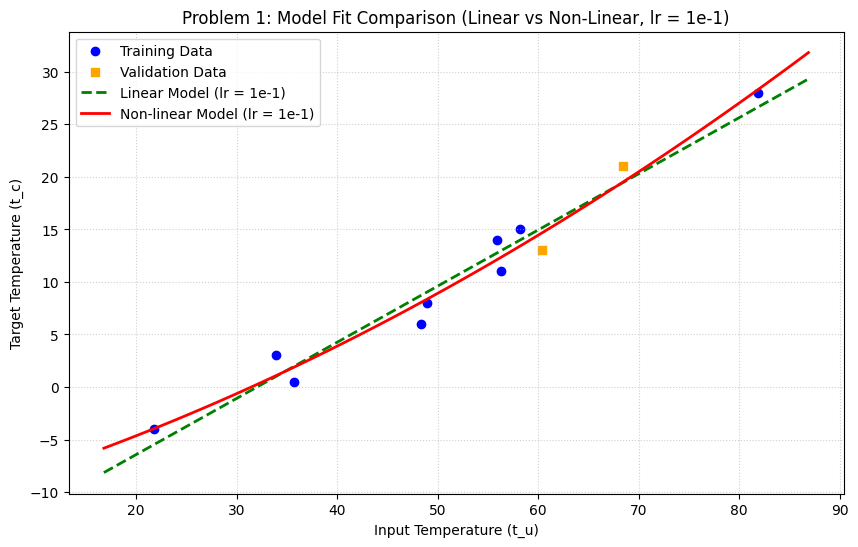

In [28]:
import numpy as np
import matplotlib.pyplot as plt

t_u_range = torch.linspace(t_u.min() - 5, t_u.max() + 5, 100)
t_un_range = 0.1 * t_u_range

with torch.no_grad():
    w1_lin, b_lin = lin_params
    pred_lin = lin_model(t_un_range, w1_lin, b_lin)

with torch.no_grad():
    w1_nonlin, w2_nonlin, b_nonlin = nonlin_1e1_params
    pred_nonlin = nonlin_model(t_un_range, w1_nonlin, w2_nonlin, b_nonlin)

plt.figure(figsize=(10, 6))
plt.scatter(t_un_train.numpy() * 10, t_c_train.numpy(), color='blue', marker='o', label='Training Data')
plt.scatter(t_un_val.numpy() * 10, t_c_val.numpy(), color='orange', marker='s', label='Validation Data')

plt.plot(t_u_range.numpy(), pred_lin.numpy(), color='green', linestyle='--', linewidth=2, label='Linear Model (lr = 1e-1)')
plt.plot(t_u_range.numpy(), pred_nonlin.numpy(), color='red', linestyle='-', linewidth=2, label='Non-linear Model (lr = 1e-1)')

plt.title('Problem 1: Model Fit Comparison (Linear vs Non-Linear, lr = 1e-1)')
plt.xlabel('Input Temperature (t_u)')
plt.ylabel('Target Temperature (t_c)')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.show()

## Problem 2: Housing Prices (5 variable)

### Preprocessing and Feature Selection

In [29]:
df_housing = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/Datasets/Housing.csv")

binary_cols = ['mainroad','guestroom','basement','hotwaterheating','airconditioning','prefarea']
binary_map = {'yes': 1, 'no': 0}

df_housing[binary_cols] = df_housing[binary_cols].replace(binary_map)
df_housing_clean = df_housing.dropna(subset=binary_cols + ['area', 'bedrooms', 'bathrooms', 'stories', 'price'])

/tmp/ipykernel_1286/3446758319.py:6: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_housing[binary_cols] = df_housing[binary_cols].replace(binary_map)


### Model Functions


In [30]:
def housing_model(X, w, b):
    return torch.matmul(X, w) + b

In [31]:
def housing_loss(y_p, y_t):
    return ((y_p - y_t) ** 2).mean()

In [32]:
def train_housing_config(lr_str, optimizer, params, n_epochs=5000):
    weights, bias = params
    print(f"--- Training with lr = {lr_str} ---")
    train_history = []
    val_history = []
    for epoch in range(1, n_epochs + 1):
        y_p_train = housing_model(X_train, weights, bias)
        train_loss = housing_loss(y_p_train, y_train)

        with torch.no_grad():
            y_p_val = housing_model(X_val, weights, bias)
            val_loss = housing_loss(y_p_val, y_val)

        optimizer.zero_grad()
        train_loss.backward()
        optimizer.step()

        train_history.append(train_loss.item())
        val_history.append(val_loss.item())

        if epoch % 500 == 0 or epoch == 1:
            print(f"Epoch {epoch:4d} | Train Loss: {train_loss.item():.6f} | Val Loss: {val_loss.item():.6f}")
    print("Learned Weights:")
    for name, w in zip(features, weights.detach().numpy()):
        print(f"  {name:10s} : {w:.4f}")
    print(f"  Bias       : {bias.item():.4f}\n")
    return train_history, val_history

### Training

In [33]:
features = ['area', 'bedrooms', 'bathrooms', 'stories', 'parking']
X_housing = df_housing_clean[features].values
Y_housing = df_housing_clean['price'].values

# 80/20 split
X_train_raw, X_val_raw, y_train_raw, y_val_raw = train_test_split(
    X_housing, Y_housing, test_size=0.2, random_state=5105
)

# Standardizations
scaler_X = StandardScaler()
X_train_scaled = scaler_X.fit_transform(X_train_raw)
X_val_scaled = scaler_X.transform(X_val_raw)

scaler_y = StandardScaler()
y_train_scaled = scaler_y.fit_transform(y_train_raw.reshape(-1, 1)).flatten()
y_val_scaled = scaler_y.transform(y_val_raw.reshape(-1, 1)).flatten()

X_train = torch.tensor(X_train_scaled, dtype=torch.float32)
X_val = torch.tensor(X_val_scaled, dtype=torch.float32)
y_train = torch.tensor(y_train_scaled, dtype=torch.float32)
y_val = torch.tensor(y_val_scaled, dtype=torch.float32)

# Parameter initialization
params_1e1 = (torch.randn(5, requires_grad=True, dtype=torch.float32), torch.randn(1, requires_grad=True, dtype=torch.float32))
params_1e2 = (torch.randn(5, requires_grad=True, dtype=torch.float32), torch.randn(1, requires_grad=True, dtype=torch.float32))
params_1e3 = (torch.randn(5, requires_grad=True, dtype=torch.float32), torch.randn(1, requires_grad=True, dtype=torch.float32))
params_1e4 = (torch.randn(5, requires_grad=True, dtype=torch.float32), torch.randn(1, requires_grad=True, dtype=torch.float32))

# Optimizers
opt_1e1 = optim.Adam(list(params_1e1), lr=1e-1)
opt_1e2 = optim.Adam(list(params_1e2), lr=1e-2)
opt_1e3 = optim.Adam(list(params_1e3), lr=1e-3)
opt_1e4 = optim.Adam(list(params_1e4), lr=1e-4)

# Training
hist_p2_1e1_t, hist_p2_1e1_v = train_housing_config("1e-1", opt_1e1, params_1e1)
hist_p2_1e2_t, hist_p2_1e2_v = train_housing_config("1e-2", opt_1e2, params_1e2)
hist_p2_1e3_t, hist_p2_1e3_v = train_housing_config("1e-3", opt_1e3, params_1e3)
hist_p2_1e4_t, hist_p2_1e4_v = train_housing_config("1e-4", opt_1e4, params_1e4)

--- Training with lr = 1e-1 ---
Epoch    1 | Train Loss: 2.542176 | Val Loss: 2.994727
Epoch  500 | Train Loss: 0.430387 | Val Loss: 0.514721
Epoch 1000 | Train Loss: 0.430387 | Val Loss: 0.514721
Epoch 1500 | Train Loss: 0.430387 | Val Loss: 0.514721
Epoch 2000 | Train Loss: 0.430387 | Val Loss: 0.514721
Epoch 2500 | Train Loss: 0.430387 | Val Loss: 0.514721
Epoch 3000 | Train Loss: 0.430387 | Val Loss: 0.514721
Epoch 3500 | Train Loss: 0.430387 | Val Loss: 0.514721
Epoch 4000 | Train Loss: 0.430387 | Val Loss: 0.514721
Epoch 4500 | Train Loss: 0.430388 | Val Loss: 0.514830
Epoch 5000 | Train Loss: 0.431593 | Val Loss: 0.521415
Learned Weights:
  area       : 0.3539
  bedrooms   : 0.0467
  bathrooms  : 0.2883
  stories    : 0.2247
  parking    : 0.2135
  Bias       : 0.0023

--- Training with lr = 1e-2 ---
Epoch    1 | Train Loss: 4.955656 | Val Loss: 7.275588
Epoch  500 | Train Loss: 0.430748 | Val Loss: 0.514789
Epoch 1000 | Train Loss: 0.430387 | Val Loss: 0.514721
Epoch 1500 | Tra

## Problem 3: Housing Prices (11 variable)

### Model Functions

In [34]:
def train_all_features_config(lr_str, optimizer, params, n_epochs=5000):
    weights, bias = params
    print(f"--- Training all features with lr = {lr_str} ---")
    train_history = []
    val_history = []
    for epoch in range(1, n_epochs + 1):
        y_p_train = torch.matmul(X_train2, weights) + bias
        train_loss = ((y_p_train - y_train2) ** 2).mean()

        with torch.no_grad():
            y_p_val = torch.matmul(X_val2, weights) + bias
            val_loss = ((y_p_val - y_val2) ** 2).mean()

        optimizer.zero_grad()
        train_loss.backward()
        optimizer.step()

        train_history.append(train_loss.item())
        val_history.append(val_loss.item())

        if epoch % 500 == 0 or epoch == 1:
            print(f"Epoch {epoch:4d} | Train Loss: {train_loss.item():.6f} | Val Loss: {val_loss.item():.6f}")
    print("Learned Weights:")
    for name, w in zip(all_features, weights.detach().numpy()):
        print(f"  {name:20s} : {w:.4f}")
    print(f"  Bias                 : {bias.item():.4f}\n")
    return train_history, val_history

### Training

In [35]:
all_features = [col for col in df_housing_clean.columns if col not in ['price', 'furnishingstatus']]

X_all = df_housing_clean[all_features].values.astype(np.float32)
Y_all = df_housing_clean['price'].values.astype(np.float32)

# 80/20 split
X_train_raw2, X_val_raw2, y_train_raw2, y_val_raw2 = train_test_split(
    X_all, Y_all, test_size=0.2, random_state=5105
)

# Standardization
scaler_X2 = StandardScaler()
X_train_scaled2 = scaler_X2.fit_transform(X_train_raw2)
X_val_scaled2 = scaler_X2.transform(X_val_raw2)

scaler_y2 = StandardScaler()
y_train_scaled2 = scaler_y2.fit_transform(y_train_raw2.reshape(-1, 1)).flatten()
y_val_scaled2 = scaler_y2.transform(y_val_raw2.reshape(-1, 1)).flatten()

X_train2 = torch.tensor(X_train_scaled2, dtype=torch.float32)
X_val2 = torch.tensor(X_val_scaled2, dtype=torch.float32)
y_train2 = torch.tensor(y_train_scaled2, dtype=torch.float32)
y_val2 = torch.tensor(y_val_scaled2, dtype=torch.float32)

# Parameter initialization
num_features = X_train2.shape[1]
params_all_1e1 = (torch.randn(num_features, requires_grad=True, dtype=torch.float32), torch.randn(1, requires_grad=True, dtype=torch.float32))
params_all_1e2 = (torch.randn(num_features, requires_grad=True, dtype=torch.float32), torch.randn(1, requires_grad=True, dtype=torch.float32))
params_all_1e3 = (torch.randn(num_features, requires_grad=True, dtype=torch.float32), torch.randn(1, requires_grad=True, dtype=torch.float32))
params_all_1e4 = (torch.randn(num_features, requires_grad=True, dtype=torch.float32), torch.randn(1, requires_grad=True, dtype=torch.float32))

# Optimizers
opt_all_1e1 = optim.Adam(list(params_all_1e1), lr=1e-1)
opt_all_1e2 = optim.Adam(list(params_all_1e2), lr=1e-2)
opt_all_1e3 = optim.Adam(list(params_all_1e3), lr=1e-3)
opt_all_1e4 = optim.Adam(list(params_all_1e4), lr=1e-4)

# Training
hist_p3_1e1_t, hist_p3_1e1_v = train_all_features_config("1e-1", opt_all_1e1, params_all_1e1)
hist_p3_1e2_t, hist_p3_1e2_v = train_all_features_config("1e-2", opt_all_1e2, params_all_1e2)
hist_p3_1e3_t, hist_p3_1e3_v = train_all_features_config("1e-3", opt_all_1e3, params_all_1e3)
hist_p3_1e4_t, hist_p3_1e4_v = train_all_features_config("1e-4", opt_all_1e4, params_all_1e4)

--- Training all features with lr = 1e-1 ---
Epoch    1 | Train Loss: 5.144393 | Val Loss: 5.746523
Epoch  500 | Train Loss: 0.324183 | Val Loss: 0.379193
Epoch 1000 | Train Loss: 0.324183 | Val Loss: 0.379189
Epoch 1500 | Train Loss: 0.324233 | Val Loss: 0.376701
Epoch 2000 | Train Loss: 0.324252 | Val Loss: 0.382069
Epoch 2500 | Train Loss: 0.324183 | Val Loss: 0.379209
Epoch 3000 | Train Loss: 0.324183 | Val Loss: 0.379193
Epoch 3500 | Train Loss: 0.324183 | Val Loss: 0.379186
Epoch 4000 | Train Loss: 0.324193 | Val Loss: 0.378691
Epoch 4500 | Train Loss: 0.324183 | Val Loss: 0.379193
Epoch 5000 | Train Loss: 0.324184 | Val Loss: 0.379360
Learned Weights:
  area                 : 0.2621
  bedrooms             : 0.0515
  bathrooms            : 0.2608
  stories              : 0.2096
  mainroad             : 0.0893
  guestroom            : 0.0621
  basement             : 0.0948
  hotwaterheating      : 0.1395
  airconditioning      : 0.2088
  parking              : 0.1807
  prefarea   

## Plotting

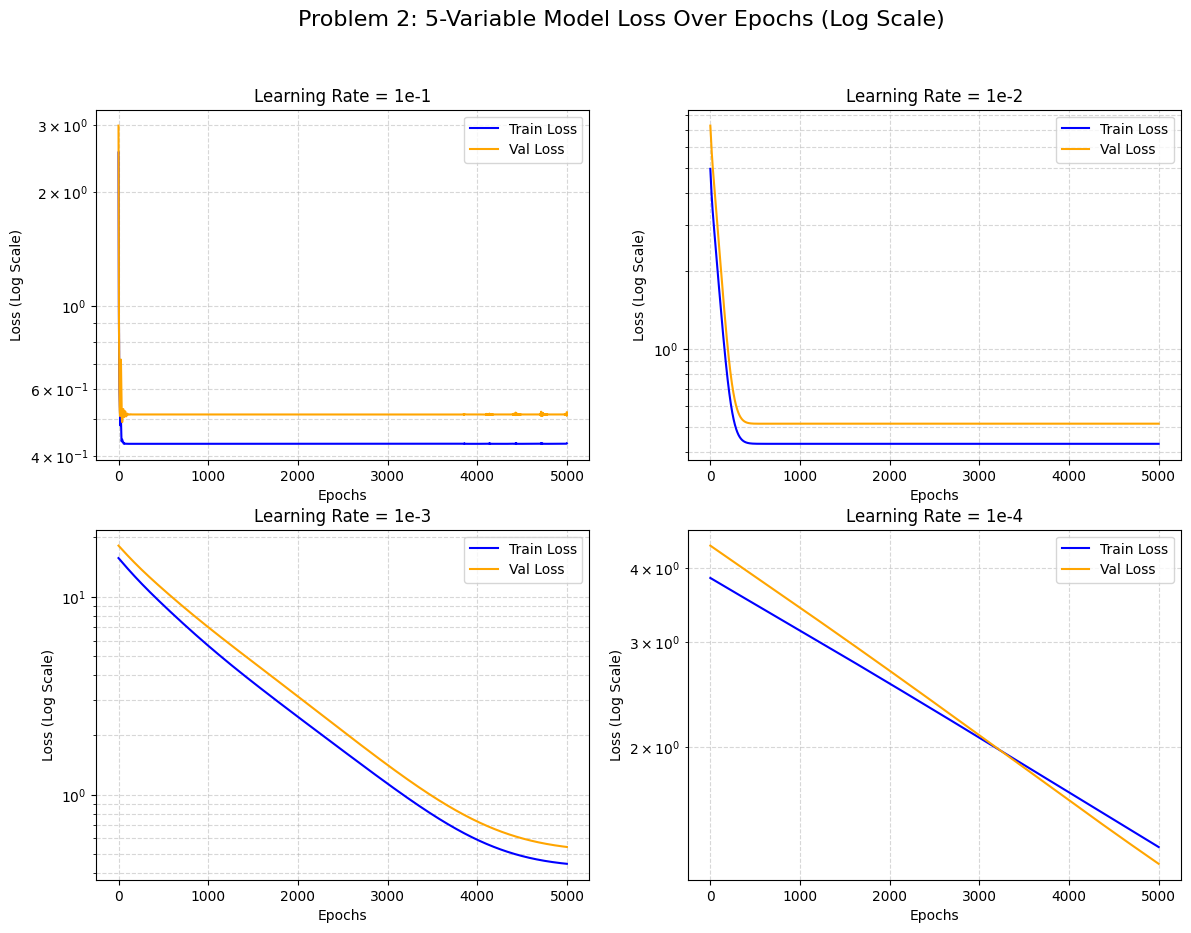

In [36]:
# Plotting for Problem 2 (with log-scaled y-axis for better visibility)
fig, axs = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Problem 2: 5-Variable Model Loss Over Epochs (Log Scale)', fontsize=16)

lrs = ["1e-1", "1e-2", "1e-3", "1e-4"]
hists_p2_t = [hist_p2_1e1_t, hist_p2_1e2_t, hist_p2_1e3_t, hist_p2_1e4_t]
hists_p2_v = [hist_p2_1e1_v, hist_p2_1e2_v, hist_p2_1e3_v, hist_p2_1e4_v]

for i, ax in enumerate(axs.flat):
    ax.plot(hists_p2_t[i], label='Train Loss', color='blue')
    ax.plot(hists_p2_v[i], label='Val Loss', color='orange')
    ax.set_title(f'Learning Rate = {lrs[i]}')
    ax.set_xlabel('Epochs')
    ax.set_ylabel('Loss (Log Scale)')
    ax.set_yscale('log')
    ax.legend()
    ax.grid(True, which="both", linestyle="--", alpha=0.5)

#plt.tight_layout()
plt.savefig('problem2_losses.png', dpi=300)
plt.show()

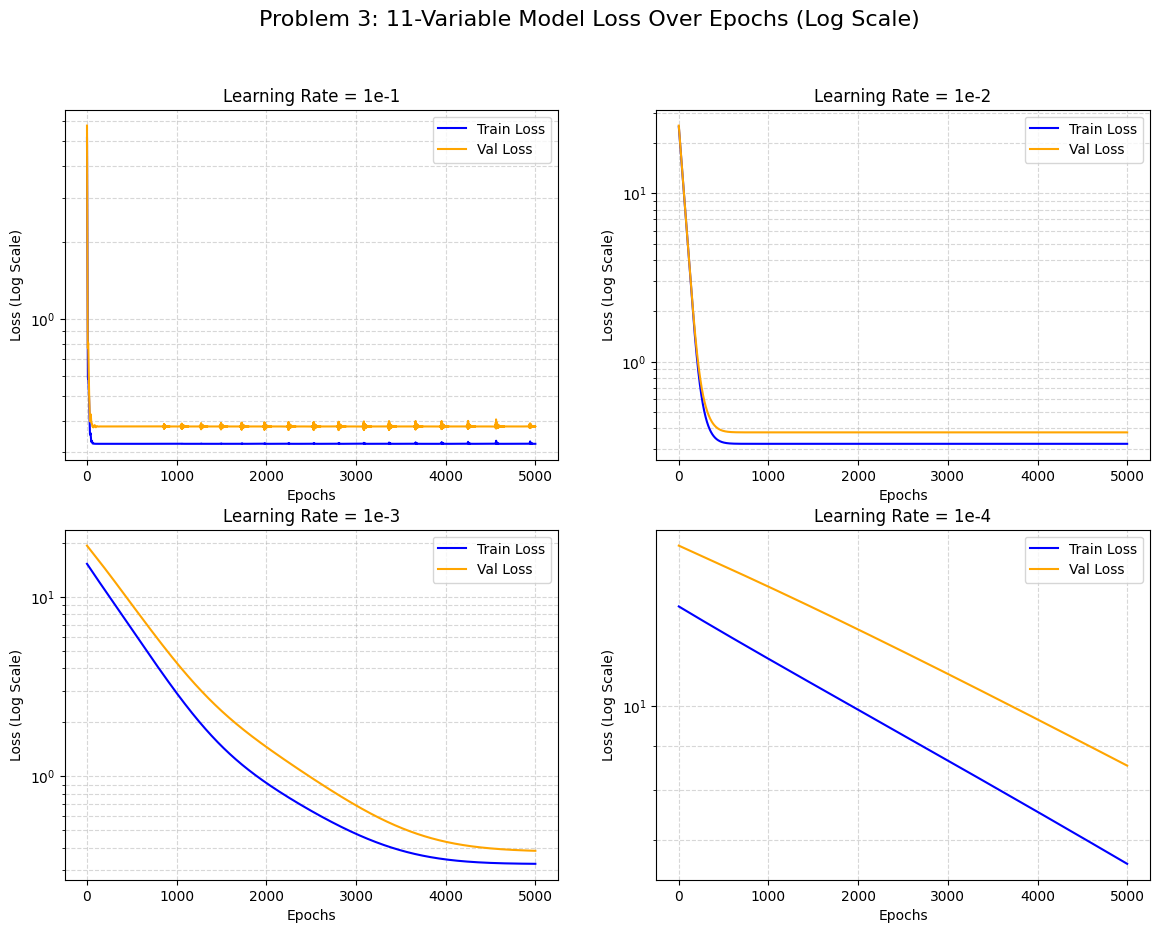

In [38]:
# Plotting for Problem 3 (with log-scaled y-axis for better visibility)
fig2, axs2 = plt.subplots(2, 2, figsize=(14, 10))
fig2.suptitle('Problem 3: 11-Variable Model Loss Over Epochs (Log Scale)', fontsize=16)

hists_p3_t = [hist_p3_1e1_t, hist_p3_1e2_t, hist_p3_1e3_t, hist_p3_1e4_t]
hists_p3_v = [hist_p3_1e1_v, hist_p3_1e2_v, hist_p3_1e3_v, hist_p3_1e4_v]

for i, ax in enumerate(axs2.flat):
    ax.plot(hists_p3_t[i], label='Train Loss', color='blue')
    ax.plot(hists_p3_v[i], label='Val Loss', color='orange')
    ax.set_title(f'Learning Rate = {lrs[i]}')
    ax.set_xlabel('Epochs')
    ax.set_ylabel('Loss (Log Scale)')
    ax.set_yscale('log')
    ax.legend()
    ax.grid(True, which="both", linestyle="--", alpha=0.5)

#plt.tight_layout()
plt.savefig('problem3_losses.png', dpi=300)
plt.show()

In [40]:
import numpy as np
import torch

# Helper function to evaluate model metrics
def evaluate_housing_metrics(model_name, X, y, weights, bias, scaler_y):
    with torch.no_grad():
        y_pred_scaled = (torch.matmul(X, weights) + bias).numpy()
        y_true_scaled = y.numpy()

    # Standardized Metrics
    std_mse = np.mean((y_pred_scaled - y_true_scaled) ** 2)
    std_mae = np.mean(np.abs(y_pred_scaled - y_true_scaled))

    # Unstandardize Predictions & Ground Truths back to actual Dollars ($)
    y_pred_unscaled = scaler_y.inverse_transform(y_pred_scaled.reshape(-1, 1)).flatten()
    y_true_unscaled = scaler_y.inverse_transform(y_true_scaled.reshape(-1, 1)).flatten()

    # Unstandardized Metrics
    unstd_mae = np.mean(np.abs(y_pred_unscaled - y_true_unscaled))
    unstd_rmse = np.sqrt(np.mean((y_pred_unscaled - y_true_unscaled) ** 2))

    return std_mse, std_mae, unstd_mae, unstd_rmse

lrs = ["1e-1", "1e-2", "1e-3", "1e-4"]

print("========== PROBLEM 2 FINAL METRICS (5 FEATURES) ==========")
p2_params_list = [params_1e1, params_1e2, params_1e3, params_1e4]

for lr, (w, b) in zip(lrs, p2_params_list):
    # Evaluated on Validation Set
    std_mse, std_mae, unstd_mae, unstd_rmse = evaluate_housing_metrics(
        f"Problem 2 (lr={lr})", X_val, y_val, w, b, scaler_y
    )
    print(f"Learning Rate: {lr}")
    print(f"  [Standardized]   MSE: {std_mse:.4f} | MAE: {std_mae:.4f}")
    print(f"  [Unstandardized] RMSE: {unstd_rmse:.2f} | MAE: {unstd_mae:.2f}")
    print("-" * 50)

print("\n========== PROBLEM 3 FINAL METRICS (11 FEATURES) ==========")
p3_params_list = [params_all_1e1, params_all_1e2, params_all_1e3, params_all_1e4]

for lr, (w, b) in zip(lrs, p3_params_list):
    # Evaluated on Validation Set
    std_mse, std_mae, unstd_mae, unstd_rmse = evaluate_housing_metrics(
        f"Problem 3 (lr={lr})", X_val2, y_val2, w, b, scaler_y2
    )
    print(f"Learning Rate: {lr}")
    print(f"  [Standardized]   MSE: {std_mse:.4f} | MAE: {std_mae:.4f}")
    print(f"  [Unstandardized] RMSE: {unstd_rmse:.2f} | MAE: {unstd_mae:.2f}")
    print("-" * 50)

========== PROBLEM 2 FINAL METRICS (5 FEATURES) ==========
Learning Rate: 1e-1
  [Standardized]   MSE: 0.5106 | MAE: 0.5255
  [Unstandardized] RMSE: 1327400.62 | MAE: 976253.06
--------------------------------------------------
Learning Rate: 1e-2
  [Standardized]   MSE: 0.5147 | MAE: 0.5265
  [Unstandardized] RMSE: 1332748.62 | MAE: 977966.44
--------------------------------------------------
Learning Rate: 1e-3
  [Standardized]   MSE: 0.5435 | MAE: 0.5585
  [Unstandardized] RMSE: 1369526.75 | MAE: 1037423.62
--------------------------------------------------
Learning Rate: 1e-4
  [Standardized]   MSE: 1.2704 | MAE: 0.8989
  [Unstandardized] RMSE: 2093826.00 | MAE: 1669791.12
--------------------------------------------------

========== PROBLEM 3 FINAL METRICS (11 FEATURES) ==========
Learning Rate: 1e-1
  [Standardized]   MSE: 0.3788 | MAE: 0.4546
  [Unstandardized] RMSE: 1143311.25 | MAE: 844576.50
--------------------------------------------------
Learning Rate: 1e-2
  [Standardiz